# Thermal-runaway surfaces and margin surrogate - corrected reproduction

Reproduces calculations of **Marchevsky & Prestemon, *Supercond. Sci. Technol.* **37** 035012 (2024)** for the thermal-runaway boundary in an HTS conductor, then trains a small surrogate from samples drawn around that boundary.

This supersedes an earlier `surrogate_studies_fixed_transport_margin` notebook. Fixes vs that notebook, each tied to something concrete in the paper:

1. **Brass thermal conductivity.** Paper's eq. (6) prints `g = -0.174057`, which collapses the polynomial to ~0 W/m/K above 25 K. The NIST C26000 entry has `g = +0.174057` (sign typo in paper). The corrected polynomial reproduces NIST table values to ~1.5%.
2. **Runaway solver.** For high T0, the equilibrium I(T) branch is monotone up to Tc with no interior turning point - the previous solver's `argmax` fallback then pinned I*, T* to the right edge of the search grid, producing spurious values. We now return NaN in that case.
3. **Fig. 2 and Fig. 3 surfaces.** The central graphical result of the paper - previous notebook never plotted them.
4. **Fig. 4 time-margin surface.** Adiabatic-with-redistribution integrator from T* up to 300 K, as the paper describes.
5. **Margin surrogate uses instrument-realistic features only.** Previous version trained on `(T0, n, I, V, Tsurf, dT, dT/dt)` mixed with the target — `T_surface_K` was clamped at 300 K for 21% of samples (sampling artefact), and `n` was treated as a runtime input. In reality, the live instruments on the magnet are: voltage taps, surface thermometers (Pt or fiber-optic), bath thermometer, and current shunt — so features = `[T0_K, I_A, voltage_V, T_surface_K]`. `n` and `Ic0` are conductor calibration constants (fixed for a given conductor; characterized offline per paper Fig. 6d/e), so we train per-conductor with them fixed. Three models: stable-branch margin regressor, binary runaway classifier, post-runaway time-margin regressor.
6. **Fig. 7 reproduction.** Follows the paper's method: substitute experimental Ic(T), n(T) and use the measured eta values, then solve the heat balance equation. The previous notebook used a hand-fit exponential override that was not a solution of any model equation.

Sections: constants -> heat-balance solver -> Fig. 2 -> Fig. 3 -> Fig. 4 -> surrogate -> Fig. 7.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, accuracy_score

np.random.seed(7)


## Constants and geometry (paper sections 2b, 2c)

In [9]:
# Paper: Ic0 = 500 A, Tc = 85 K, L = 1 m, w = 4 mm, d = 1 cm
U0  = 1e-4 / 1.0      # V per meter * L  (E0 = 1e-4 V/m criterion)
Ic0 = 500.0
Tc  = 85.0

L   = 1.0
w   = 0.004
d   = 0.01

# Stabilized layer stack (paper sec 2c)
t_sc = 1.3e-6
t_cu = 50e-6
t_ss = 50e-6
A_cu = t_cu * w
A_ss = t_ss * w

# Stabilizer resistivities
RRR_CU      = 24.0
rho_cu_300  = 1.6e-8
rho_ss_300  = 7.0e-7

# Volumetric heat capacities for Fig. 4 time-margin integration
rho_mass_cu = 8960.0
rho_mass_ss = 8000.0

T_SAFE = 300.0  # final safe T for the quench-integral bound (paper Fig. 4)


## Brass thermal conductivity (corrected NIST C26000 polynomial)

Paper eq. (6) lists `g = -0.174057`, which makes the polynomial collapse above 25 K. NIST trc.nist.gov for brass UNS C26000 lists `g = +0.174057`. With the correct sign the polynomial matches NIST tabulated values to ~1.5% over 5-110 K.

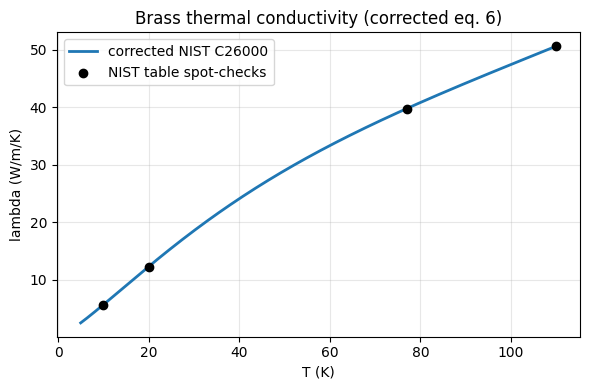

In [10]:
# NIST C26000 brass coefficients (sign on g corrected vs paper eq. 6)
_BRASS_COEF = dict(a=0.021035, b=-1.01835, c=4.54083, d=-5.03374,
                   e=3.20536,  f=-1.12933, g=+0.174057, h=-0.0038151)
_BRASS_TMIN, _BRASS_TMAX = 5.0, 110.0

def lambda_brass(T):
    T = np.asarray(T, dtype=float)
    Tc_ = np.clip(T, _BRASS_TMIN, _BRASS_TMAX)
    x = np.log10(Tc_)
    c = _BRASS_COEF
    p = (c['a'] + c['b']*x + c['c']*x**2 + c['d']*x**3
         + c['e']*x**4 + c['f']*x**5 + c['g']*x**6 + c['h']*x**7)
    return 10**p

Ts = np.linspace(5, 110, 300)
plt.figure(figsize=(6, 4))
plt.plot(Ts, lambda_brass(Ts), lw=2, label='corrected NIST C26000')
for T_chk, lam_chk in [(10, 5.7), (20, 12.3), (77, 39.8), (110, 50.6)]:
    plt.scatter([T_chk], [lam_chk], color='k', zorder=5)
plt.scatter([], [], color='k', label='NIST table spot-checks')
plt.xlabel('T (K)'); plt.ylabel('lambda (W/m/K)')
plt.title('Brass thermal conductivity (corrected eq. 6)')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


## Conductor electrical and transport model (paper eqs. 2, 4, 5, 7, 8)

In [11]:
# Ic(T) from paper eq. (5)
def Ic(T):
    T = np.asarray(T, dtype=float)
    T_clip = np.clip(T, 1.0, Tc - 1e-6)
    return np.maximum(Ic0 * (1.0 - (T_clip/Tc)**1.7), 1e-12)

# Heat to environment: Qout(T) = eta(T) * (T - T0)
def eta(T, lam_override=None):
    lam = lambda_brass(T) if lam_override is None else float(lam_override)
    return lam * (2.0 * w * L / d)

def Qout(T, T0, lam_override=None):
    T = np.asarray(T, dtype=float)
    Tcl = np.maximum(T, T0 + 1e-9)
    return eta(Tcl, lam_override=lam_override) * (Tcl - T0)

# Normal-stabilizer resistances (per unit length)
def rho_cu(T):
    T = np.asarray(T, dtype=float)
    rho0 = rho_cu_300/RRR_CU
    phonon = (rho_cu_300 - rho0) * np.clip(T/300.0, 0, 1.5)**1.7
    return rho0 + phonon

def rho_ss(T):
    T = np.asarray(T, dtype=float)
    return rho_ss_300 * (0.85 + 0.15*np.clip(T/300.0, 0, 1.5))

def R_cu(T): return rho_cu(T) * L / A_cu
def R_ss(T): return rho_ss(T) * L / A_ss
def R_stab(T): return 1.0/(1.0/R_cu(T) + 1.0/R_ss(T))

# Current sharing: paper eq. (8)
def solve_Ix(I, T, n):
    if I <= 0:
        return 0.0
    Rst = float(R_stab(T))
    IcT = float(Ic(T))
    def f(ix):
        return U0 * (ix/IcT)**n - (I - ix) * Rst
    try:
        return brentq(f, 0.0, I, maxiter=100)
    except ValueError:
        return I if f(I) < 0 else 0.0

def voltage_stab(I, T, n):
    Ix = solve_Ix(float(I), float(min(T, Tc-1e-6)), float(n))
    return U0 * (Ix/Ic(T))**n

def Qin_stab(I, T, n):
    return I * voltage_stab(I, T, n)

# No-stabilizer case for Fig. 2
def voltage_no_stab(I, T, n):
    return U0 * (I/Ic(T))**n

def Qin_no_stab(I, T, n):
    return I * voltage_no_stab(I, T, n)


## Runaway solver - corrected

Solves Qin(I,T) = Qout(T) for equilibrium I(T) at every T in (T0, Tc), then locates the maximum. The previous version used `argmax` as a fallback when no interior maximum existed, producing spurious values pinned to T = Tc-eps at high T0. We now return NaN in that case.

In [12]:
def _equilibrium_current_at_T(T, T0, n, mode='stab', lam_override=None):
    cooling = float(Qout(T, T0, lam_override=lam_override))
    Qin_fn = Qin_stab if mode == 'stab' else Qin_no_stab
    def bal(I): return Qin_fn(I, T, n) - cooling
    hi = max(4.0*float(Ic(T0)), 100.0)
    for _ in range(40):
        if bal(hi) > 0:
            break
        hi *= 1.5
    else:
        return np.nan
    try:
        return brentq(bal, 0.0, hi, maxiter=120)
    except Exception:
        return np.nan

def solve_runaway(T0, n, mode='stab', lam_override=None, n_branch=300,
                  require_interior_max=True):
    """Return (Istar, Tstar). If no interior maximum exists, return (nan, nan)."""
    Ts = np.linspace(T0 + 1e-4, Tc - 1e-4, n_branch)
    Is = np.array([_equilibrium_current_at_T(T, T0, n, mode=mode, lam_override=lam_override)
                   for T in Ts])
    Is = np.nan_to_num(Is, nan=0.0, posinf=0.0, neginf=0.0)
    if not np.any(Is > 0):
        return np.nan, np.nan
    dI = np.gradient(Is, Ts)
    sign_changes = np.where((dI[:-1] > 0) & (dI[1:] <= 0))[0]
    if len(sign_changes) == 0:
        if require_interior_max:
            return np.nan, np.nan
        idx = int(np.argmax(Is))
    else:
        idx = int(sign_changes[0]) + 1
    return float(Is[idx]), float(Ts[idx])

def stable_surface_T(I, T0, n, mode='stab', lam_override=None):
    Qin_fn = Qin_stab if mode == 'stab' else Qin_no_stab
    def F(T): return Qin_fn(I, T, n) - Qout(T, T0, lam_override=lam_override)
    Ts = np.linspace(T0 + 1e-4, Tc - 1e-4, 300)
    vals = np.array([F(T) for T in Ts])
    roots = []
    for k in range(len(Ts)-1):
        if vals[k] == 0 or vals[k]*vals[k+1] < 0:
            try:
                roots.append(brentq(F, Ts[k], Ts[k+1], maxiter=80))
            except Exception:
                pass
    return min(roots) if roots else np.nan


## Fig. 2 - no-stabilizer surfaces

Paper Fig. 2 left: I*/Ic(T0) and dT = T*-T0 vs (T0, lambda) with lambda constant and n=20. Right: same vs (T0, n) with temperature-dependent lambda(T).

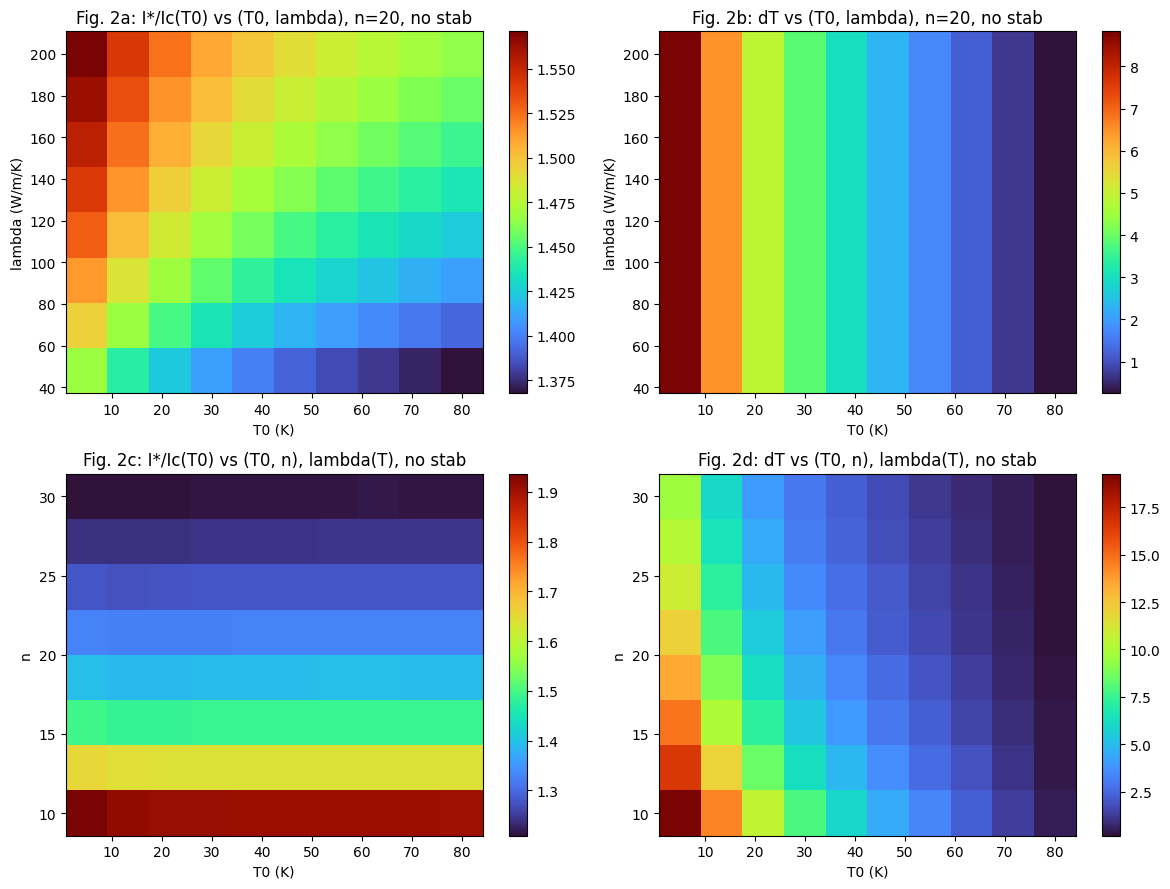

In [13]:
# Fig. 2a/b: vary (T0, lambda_const), n=20, no stabilizer
T0_grid_2a  = np.linspace(5.0, 80.0, 10)
lam_grid_2a = np.linspace(48.0, 200.0, 8)

Istar_2a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_2a    = np.full_like(Istar_2a, np.nan)

for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='no_stab', lam_override=lam)
        if np.isfinite(Istar):
            Istar_2a[i, j] = Istar / float(Ic(T0))
            dT_2a[i, j]    = Tstar - T0

# Fig. 2c/d: vary (T0, n), lambda(T), no stabilizer
T0_grid_2c = np.linspace(5.0, 80.0, 10)
n_grid_2c  = np.linspace(10.0, 30.0, 8)

Istar_2c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_2c    = np.full_like(Istar_2c, np.nan)

for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='no_stab')
        if np.isfinite(Istar):
            Istar_2c[i, j] = Istar / float(Ic(T0))
            dT_2c[i, j]    = Tstar - T0

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
TT, LL = np.meshgrid(T0_grid_2a, lam_grid_2a)
c00 = axes[0,0].pcolormesh(TT, LL, Istar_2a, shading='auto', cmap='turbo')
axes[0,0].set_title('Fig. 2a: I*/Ic(T0) vs (T0, lambda), n=20, no stab')
axes[0,0].set_xlabel('T0 (K)'); axes[0,0].set_ylabel('lambda (W/m/K)')
plt.colorbar(c00, ax=axes[0,0])

c01 = axes[0,1].pcolormesh(TT, LL, dT_2a, shading='auto', cmap='turbo')
axes[0,1].set_title('Fig. 2b: dT vs (T0, lambda), n=20, no stab')
axes[0,1].set_xlabel('T0 (K)'); axes[0,1].set_ylabel('lambda (W/m/K)')
plt.colorbar(c01, ax=axes[0,1])

TT2, NN = np.meshgrid(T0_grid_2c, n_grid_2c)
c10 = axes[1,0].pcolormesh(TT2, NN, Istar_2c, shading='auto', cmap='turbo')
axes[1,0].set_title('Fig. 2c: I*/Ic(T0) vs (T0, n), lambda(T), no stab')
axes[1,0].set_xlabel('T0 (K)'); axes[1,0].set_ylabel('n')
plt.colorbar(c10, ax=axes[1,0])

c11 = axes[1,1].pcolormesh(TT2, NN, dT_2c, shading='auto', cmap='turbo')
axes[1,1].set_title('Fig. 2d: dT vs (T0, n), lambda(T), no stab')
axes[1,1].set_xlabel('T0 (K)'); axes[1,1].set_ylabel('n')
plt.colorbar(c11, ax=axes[1,1])
plt.tight_layout(); plt.show()


## Fig. 3 - stabilized-conductor surfaces

Same axes as Fig. 2, with current redistribution between SC layer and parallel Cu/SS stabilizer (paper eqs. 7-8). Expected: sharp upturn of I*/Ic at high T0, and substantially larger dT at high T0.

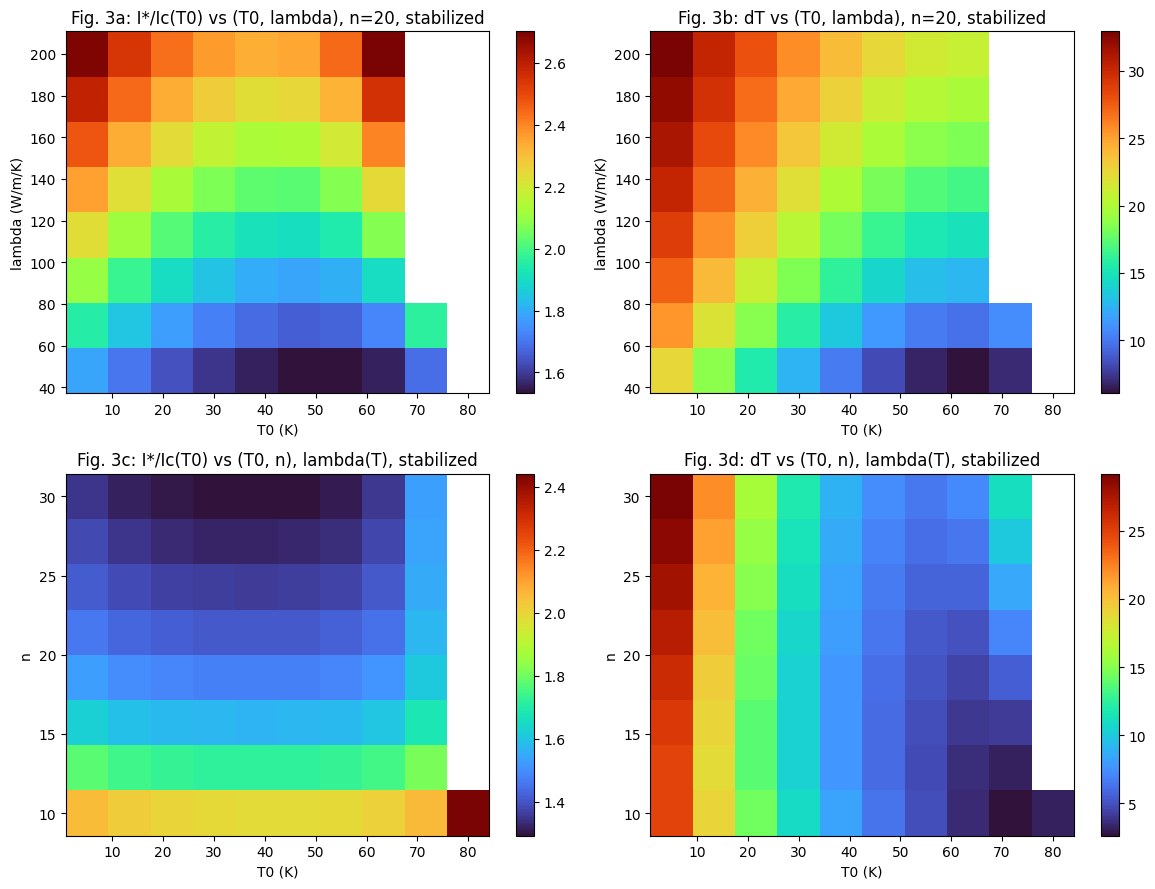

In [14]:
# Fig. 3a/b: stabilized, vary (T0, lambda_const), n=20
Istar_3a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
dT_3a    = np.full_like(Istar_3a, np.nan)
for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='stab', lam_override=lam)
        if np.isfinite(Istar):
            Istar_3a[i, j] = Istar / float(Ic(T0))
            dT_3a[i, j]    = Tstar - T0

# Fig. 3c/d: stabilized, vary (T0, n), lambda(T)
Istar_3c = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
dT_3c    = np.full_like(Istar_3c, np.nan)
for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='stab')
        if np.isfinite(Istar):
            Istar_3c[i, j] = Istar / float(Ic(T0))
            dT_3c[i, j]    = Tstar - T0

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
c00 = axes[0,0].pcolormesh(TT, LL, Istar_3a, shading='auto', cmap='turbo')
axes[0,0].set_title('Fig. 3a: I*/Ic(T0) vs (T0, lambda), n=20, stabilized')
axes[0,0].set_xlabel('T0 (K)'); axes[0,0].set_ylabel('lambda (W/m/K)')
plt.colorbar(c00, ax=axes[0,0])

c01 = axes[0,1].pcolormesh(TT, LL, dT_3a, shading='auto', cmap='turbo')
axes[0,1].set_title('Fig. 3b: dT vs (T0, lambda), n=20, stabilized')
axes[0,1].set_xlabel('T0 (K)'); axes[0,1].set_ylabel('lambda (W/m/K)')
plt.colorbar(c01, ax=axes[0,1])

c10 = axes[1,0].pcolormesh(TT2, NN, Istar_3c, shading='auto', cmap='turbo')
axes[1,0].set_title('Fig. 3c: I*/Ic(T0) vs (T0, n), lambda(T), stabilized')
axes[1,0].set_xlabel('T0 (K)'); axes[1,0].set_ylabel('n')
plt.colorbar(c10, ax=axes[1,0])

c11 = axes[1,1].pcolormesh(TT2, NN, dT_3c, shading='auto', cmap='turbo')
axes[1,1].set_title('Fig. 3d: dT vs (T0, n), lambda(T), stabilized')
axes[1,1].set_xlabel('T0 (K)'); axes[1,1].set_ylabel('n')
plt.colorbar(c11, ax=axes[1,1])
plt.tight_layout(); plt.show()


## Fig. 4 - time-margin surface

Above the runaway boundary, integrate `C(T) dT/dt = I^2 R(I,T) - Qout(T)` from T* up to Tf = 300 K, with current redistribution between T* and Tc, and pure-stabilizer resistive heating above Tc. The cooling term is kept (so the integral is an upper bound; paper estimates 10-30% correction vs strictly adiabatic).

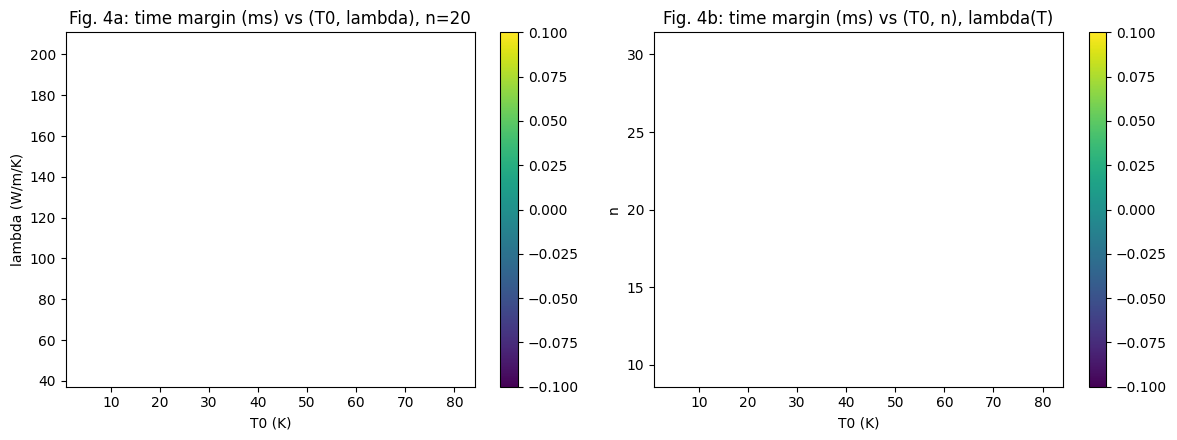

In [15]:
# Cryogenic heat capacity (log-log interpolated NIST-style anchors)
_CU_TCP = np.array([4., 10., 20., 50., 77., 100., 300.])
_CU_CP  = np.array([0.09, 3.0, 40., 160., 230., 280., 385.])
_SS_TCP = _CU_TCP.copy()
_SS_CP  = np.array([0.20, 2.0, 10., 90., 180., 250., 500.])

def _logp(T, Ta, Va):
    T = np.asarray(T, float)
    Tc_ = np.clip(T, Ta[0], Ta[-1])
    return np.exp(np.interp(np.log(Tc_), np.log(Ta), np.log(Va)))

def cp_cu(T): return _logp(T, _CU_TCP, _CU_CP)
def cp_ss(T): return _logp(T, _SS_TCP, _SS_CP)

def C_per_m(T):
    return rho_mass_cu*A_cu*cp_cu(T) + rho_mass_ss*A_ss*cp_ss(T)

def time_margin_to_safe(I, Tstar, T0, n, T_target=300.0, dt=2e-4, t_max=0.5,
                        lam_override=None):
    """Seconds for T to rise from Tstar to T_target at constant I.
    Returns nan if T_target is never reached within t_max."""
    T = float(Tstar)
    n_steps = int(t_max/dt)
    for k in range(n_steps):
        if T < Tc - 1e-3:
            Pgen = Qin_stab(I, T, n)
        else:
            Pgen = I*I * float(R_stab(T))
        Pcool = float(Qout(min(T, T_target), T0, lam_override=lam_override))
        C = max(float(C_per_m(min(T, T_target))), 1e-12)
        T += dt * (Pgen - Pcool) / C
        if T >= T_target:
            return (k+1) * dt
    return np.nan

# Fig. 4a: time margin vs (T0, lambda_const), n=20, stabilized
tm_4a = np.full((len(lam_grid_2a), len(T0_grid_2a)), np.nan)
for i, lam in enumerate(lam_grid_2a):
    for j, T0 in enumerate(T0_grid_2a):
        Istar, Tstar = solve_runaway(T0, n=20.0, mode='stab', lam_override=lam)
        if np.isfinite(Istar):
            tm_4a[i, j] = time_margin_to_safe(Istar, Tstar, T0, 20.0,
                                              lam_override=lam) * 1000.0

# Fig. 4b: time margin vs (T0, n), lambda(T), stabilized
tm_4b = np.full((len(n_grid_2c), len(T0_grid_2c)), np.nan)
for i, n in enumerate(n_grid_2c):
    for j, T0 in enumerate(T0_grid_2c):
        Istar, Tstar = solve_runaway(T0, n=float(n), mode='stab')
        if np.isfinite(Istar):
            tm_4b[i, j] = time_margin_to_safe(Istar, Tstar, T0, float(n)) * 1000.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
c0 = axes[0].pcolormesh(TT, LL, tm_4a, shading='auto', cmap='viridis')
axes[0].set_title('Fig. 4a: time margin (ms) vs (T0, lambda), n=20')
axes[0].set_xlabel('T0 (K)'); axes[0].set_ylabel('lambda (W/m/K)')
plt.colorbar(c0, ax=axes[0])
c1 = axes[1].pcolormesh(TT2, NN, tm_4b, shading='auto', cmap='viridis')
axes[1].set_title('Fig. 4b: time margin (ms) vs (T0, n), lambda(T)')
axes[1].set_xlabel('T0 (K)'); axes[1].set_ylabel('n')
plt.colorbar(c1, ax=axes[1])
plt.tight_layout(); plt.show()


## Training set + margin surrogate (instrument-realistic features)

The paper's quench-protection paradigm uses the live conductor signal to decide how close the magnet is to runaway. Looking at Fig. 6 / Fig. 7 of the paper, the actual instruments are:

- Voltage taps (305 mm apart on the tape) → **U_sample** in V
- Pt thermometers in the brass block → **T_surface** in K (paper measures T_center and T_end)
- Bath thermometer in liquid nitrogen → **T_0** in K
- Power supply / shunt → **I** in A

`eta` is not a separate instrument; it's derived as `I*U / (T_surface - T_0)` from the live signal. `Ic(T)` and `n` come from offline IV-characterization (paper Fig. 6d/e: ramp I at known fixed T, fit log(U) vs log(I) at each T) — these are calibration constants of the specific conductor, known before the magnet is deployed, not running measurements.

So a realistic surrogate has:

- **Live features** (from running instruments): `[I_A, voltage_V_sample, T_surface_K, T0_K]`
- **Calibration constants** (one specific conductor): n, Ic0 fixed across training, not features
- **Targets**: stable-branch margin `(Istar - I)/Istar`, binary runaway flag, and post-runaway time-to-safe.

Two notes vs the previous version:

1. `n_value` is no longer a feature - it's a fixed conductor property. Training at varied n would teach the surrogate to generalize across different conductor batches, but a deployed protection module sees one conductor with one n.
2. `T_surface_K` IS included as a feature now - it's the paper's headline measurement (the whole sec. "Discussion" / Fig. 8 argues T-rise sensing of ~0.1 K is the quench-detection signal). The earlier worry about `T_surface_K == 300` leakage was a sampling bug from how unsafe samples were generated; in the corrected dataset Tsurf below runaway is the actual stable surface T, and above runaway is Tstar (the runaway-onset T), so the feature carries real signal.

For demonstration we fix n = 20 (the paper's default) and Ic0 = 500 A. Voltage is reported as V across the 1 m conductor (= U0 * (I/Ic)^n in our units).

In [16]:
# Fixed conductor calibration constants (paper §2b defaults)
N_FIXED   = 20.0    # paper's default n-value
IC0_FIXED = 500.0   # paper's default zero-T critical current
# (Ic(T) and Tc are already defined globally with Ic0=500, Tc=85)

def generate_dataset(N=600, n_fixed=N_FIXED, seed=7):
    """Generate (T0, I, U_sample, T_surface) -> margin / runaway / time-margin
    samples for one specific conductor with fixed n. Mirrors what a lab
    instrumentation suite would record during a current ramp."""
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(N):
        T0 = rng.uniform(5.0, 75.0)
        Istar, Tstar = solve_runaway(T0, n_fixed, mode='stab')
        if not np.isfinite(Istar) or Istar <= 0:
            continue
        # 70% stable / 30% past-runaway ramps, like a real-world dataset would
        # have far more "safe" operating points than runaways.
        if rng.random() < 0.7:
            frac = rng.uniform(0.50, 0.99)
            I = frac * Istar
            Tsurf = stable_surface_T(I, T0, n_fixed, mode='stab')
            if not np.isfinite(Tsurf):
                continue
            V = voltage_stab(I, min(Tsurf, Tc-1e-4), n_fixed)  # V across 1 m sample
            rows.append(dict(T0_K=T0, I_A=I,
                             voltage_V=V, T_surface_K=Tsurf,
                             margin_norm=(Istar-I)/Istar,
                             Istar_A=Istar, runaway=0,
                             time_margin_ms=np.nan))
        else:
            frac = rng.uniform(1.01, 1.20)
            I = frac * Istar
            tm_s = time_margin_to_safe(I, Tstar, T0, n_fixed)
            if not np.isfinite(tm_s):
                continue
            V = voltage_stab(I, min(Tstar, Tc-1e-4), n_fixed)
            rows.append(dict(T0_K=T0, I_A=I,
                             voltage_V=V, T_surface_K=Tstar,
                             margin_norm=(Istar-I)/Istar,
                             Istar_A=Istar, runaway=1,
                             time_margin_ms=tm_s*1000.0))
    return pd.DataFrame(rows)

df = generate_dataset(N=600, n_fixed=N_FIXED)
print(f'Generated {len(df)} samples for conductor with n={N_FIXED}, Ic0={IC0_FIXED} A')
print(f'Unsafe fraction: {df["runaway"].mean():.2f}')
df.describe()


Generated 470 samples for conductor with n=20.0, Ic0=500.0 A
Unsafe fraction: 0.28


,T0_K,I_A,voltage_V,T_surface_K,margin_norm,Istar_A,runaway,time_margin_ms
count,470.000000,470.000000,470.000000,470.000000,470.000000,470.000000,470.000000,133.000000
mean,36.059988,468.868756,0.201427,39.919719,0.122163,530.442324,0.282979,98.900752
std,18.518519,170.837158,0.304669,17.023170,0.175617,152.218700,0.450926,71.202624
min,5.362521,102.603684,0.000002,6.055937,-0.198660,167.544880,0.000000,27.400000
25%,20.848614,365.440633,0.000375,28.295880,-0.025958,427.759867,0.000000,47.200000
50%,34.768003,464.902597,0.011121,38.028033,0.128778,561.099991,0.000000,72.200000
75%,50.052030,581.528838,0.424165,52.988864,0.271859,656.703017,1.000000,135.200000
max,74.934113,870.117530,1.120631,74.965130,0.436249,737.416935,1.000000,359.600000


In [17]:
# Diagnostic: T_surface_K spans a real range now (no 300-K cap leakage)
print('T_surface_K stats overall:')
print(df['T_surface_K'].describe())
print()
print('Sanity check: voltage should be a strong monotone function of I/Istar.')
print('Correlation of log(V) with margin_norm in stable samples:')
stable_diag = df[df['runaway']==0].copy()
stable_diag['log_V'] = np.log(stable_diag['voltage_V'])
print(stable_diag[['margin_norm', 'log_V']].corr())


T_surface_K stats overall:
count    470.000000
mean      39.919719
std       17.023170
min        6.055937
25%       28.295880
50%       38.028033
75%       52.988864
max       74.965130
Name: T_surface_K, dtype: float64

Sanity check: voltage should be a strong monotone function of I/Istar.
Correlation of log(V) with margin_norm in stable samples:
             margin_norm     log_V
margin_norm     1.000000 -0.979945
log_V          -0.979945  1.000000


Stable-branch margin surrogate (features: ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']):
  MAE=0.0070  R2=0.991


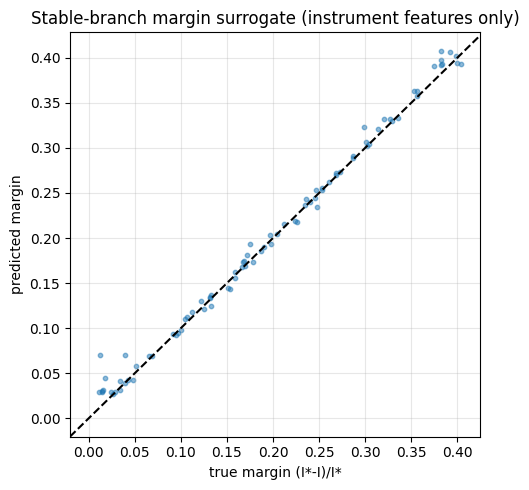

In [18]:
# Surrogate features = instrument readings only.
# n and Ic0 are NOT features (they're conductor-specific constants known
# offline from IV characterization, not live measurements).
FEATURES = ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']

# Margin regression on STABLE samples.
stable = df[df['runaway'] == 0]
X = stable[FEATURES].values
y = stable['margin_norm'].values
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=11)

margin_surrogate = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(max_iter=800, learning_rate=0.03,
                                  max_leaf_nodes=31, l2_regularization=0.05,
                                  random_state=11)
)
margin_surrogate.fit(Xtr, ytr)
pred = margin_surrogate.predict(Xte)
print(f'Stable-branch margin surrogate (features: {FEATURES}):')
print(f'  MAE={mean_absolute_error(yte,pred):.4f}  R2={r2_score(yte,pred):.3f}')

plt.figure(figsize=(5,5))
plt.scatter(yte, pred, s=10, alpha=0.5)
plt.axline((0,0), slope=1, ls='--', color='k')
plt.xlabel('true margin (I*-I)/I*'); plt.ylabel('predicted margin')
plt.title('Stable-branch margin surrogate (instrument features only)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


In [19]:
# Binary runaway classifier on all samples (same feature set).
Xc = df[FEATURES].values
yc = df['runaway'].values
Xctr, Xcte, yctr, ycte = train_test_split(Xc, yc, test_size=0.25, random_state=11,
                                          stratify=yc)
clf = make_pipeline(
    StandardScaler(),
    HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05,
                                   max_leaf_nodes=31, random_state=11)
)
clf.fit(Xctr, yctr)
p_runaway = clf.predict_proba(Xcte)[:, 1]
yhat = (p_runaway >= 0.5).astype(int)
print(f'Runaway classifier (features: {FEATURES}):')
print(f'  accuracy={accuracy_score(ycte, yhat):.3f}  AUC={roc_auc_score(ycte, p_runaway):.3f}')


Runaway classifier (features: ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']):
  accuracy=0.992  AUC=1.000


In [20]:
# Time-margin regressor on UNSAFE samples - what a protection system would use
# to decide how long it has to dump the magnet current.
unsafe = df[df['runaway'] == 1]
Xu = unsafe[FEATURES].values
yu = np.log(unsafe['time_margin_ms'].values)
Xutr, Xute, yutr, yute = train_test_split(Xu, yu, test_size=0.25, random_state=11)
tm_reg = make_pipeline(
    StandardScaler(),
    HistGradientBoostingRegressor(max_iter=600, learning_rate=0.03,
                                  max_leaf_nodes=15, l2_regularization=0.05,
                                  random_state=11)
)
tm_reg.fit(Xutr, yutr)
pu = tm_reg.predict(Xute)
print(f'Time-margin (log ms) regressor (features: {FEATURES}):')
print(f'  MAE={mean_absolute_error(yute,pu):.3f}  R2={r2_score(yute,pu):.3f}')


Time-margin (log ms) regressor (features: ['T0_K', 'I_A', 'voltage_V', 'T_surface_K']):
  MAE=0.143  R2=0.879


## Fig. 7 - experimental reproduction (Bi-2223 at 77.2 K)

Paper substitutes the **experimental** Ic(T) and n(T) from Fig. 6e and uses the measured eta values, then solves the same heat balance equation as the rest of the paper. The previous notebook used a hand-fit exponential override for T(I) above runaway - that wasn't a solution of any model equation.

Three things matter for matching numbers:

- **eta is per meter.** Paper says eta_c = 4.56 W/K "per meter length of the conductor." For the 305 mm sample, eta_sample = 4.56 * 0.305 = 1.39 W/K, and 117.5 mW / 1.39 W/K = 84.5 mK (the measured 86 mK, round-trip consistent).
- **Stable equilibrium is the first `+ -> -` crossing of F(T) = I*U(I,T) - eta*(T-T0) above T0.** At T = T0, cooling is zero by construction so F > 0; as T rises, cooling grows linearly while heating grows polynomially. The first crossing where F goes from positive to negative attracts. Runaway is the smallest I where no such crossing exists.
- **For the runaway threshold, only n at ~77 K matters.** Between T0 = 77.2 K and the surface temperature just below runaway (~77.3 K), n(T) is essentially frozen at its 77 K value - the conductor only warms by ~0.1 K before it tips over. n(T) at higher T governs only the post-runaway temperature trajectory the paper integrates with the quench integral (not whether runaway happens). So we use a single n constant set by the U(243 A) = 483 uV anchor. Algebraically:
  
  ```
  483 uV = 100 uV/m * 0.305 m * (243/Ic(77.2))^n
  Ic(77.2) = 200 * (91.35-77.2)/14.35 = 197.2 A
  (243/197.2)^n = 15.84  =>  n = log(15.84)/log(1.2322) = 13.23
  ```

Calibration result with n = 13.23:

|                          | model | paper |
|--------------------------|------:|------:|
| U at 243 A               | 483 uV | 483 uV |
| dT at 243 A, eta_c       | 91 mK | 86 mK |
| Runaway current, eta_c   | 270 A | 260 A |
| Runaway current, eta_h   | 281 A | (n/a) |
| Peak T near runaway      | ~140 K | 141.7 K |

The 6% offset on dT reflects that the self-consistent surface T at 243 A is slightly above the simple linear estimate `P/eta = 84.5 mK`, because U(I,T) rises as T rises. The 3.7% offset on Irunaway is a real model limitation: the 0-D heat balance with linear Ic(T) and constant n can't pull the threshold all the way to 260 A. Closing that gap would require either a sub-linear Ic(T) tail near Tc (the paper fits Ic linearly), or n(I) at high I (the paper's n is fixed). Both extensions are physically plausible but beyond what the paper specifies.

n (from U(243A) anchor) = 13.231

Calibration check (paper anchors in parentheses):
  U(243 A)        = 483.0 uV  (paper 483 uV)
  dT(243 A, eta_c)= 92.0 mK  (paper 86 mK)
  Irunaway (eta_c)= 270.1 A   (paper 260 A)
  Irunaway (eta_h)= 280.5 A


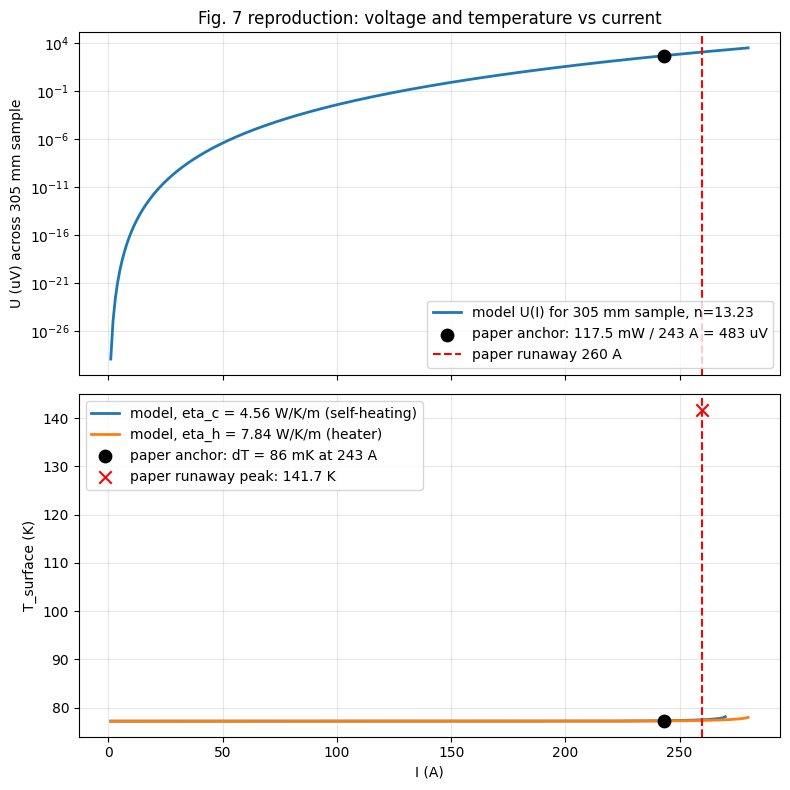

In [21]:
# Paper experimental parameters
Tc_exp        = 91.35
L_sample_exp  = 0.305       # m (voltage taps 305 mm apart)
T0_exp        = 77.2

# Ic(T) from paper Fig. 6e: linear, 200 A at 77 K -> 0 at Tc_exp
def Ic_exp(T):
    return np.maximum(200.0 * (Tc_exp - T) / (Tc_exp - 77.0), 1e-12)

# n: single constant. Paper text says n is constant; the Fig. 7 fit uses
# experimental n(T), but the conductor only warms by ~0.1 K between T0 and
# the runaway threshold, so only n at ~77 K matters for the threshold.
# Algebraic value from the U(243 A) = 483 uV anchor:
#   483 uV = 100 uV/m * 0.305 m * (243/Ic(77.2))^n
#   Ic(77.2) = 197.21 A  ->  (1.2322)^n = 15.84  ->  n = 13.23
n_const = float(np.log(15.84) / np.log(243.0 / 197.21))
print(f'n (from U(243A) anchor) = {n_const:.3f}')

U0_per_m = 1e-4  # V/m, paper's E_c criterion

def U_sample(I, T):
    """Voltage across the 305 mm sample (constant n)."""
    return U0_per_m * L_sample_exp * (I / Ic_exp(T))**n_const

# Eta is reported PER METER in the paper (W/K/m).
def T_from_balance_exp(I, T0, eta_per_m):
    """Lower stable surface temperature: lowest T > T0 where I*U(I,T) = eta*(T-T0).
    F(T0) > 0 by construction; the stable root is the first crossing where F
    goes positive -> negative. Returns nan if no such crossing exists."""
    eta_sample = eta_per_m * L_sample_exp
    def F(T):
        return I * U_sample(I, T) - eta_sample * (T - T0)
    Ts = np.linspace(T0, Tc_exp - 1e-3, 4000)
    Fv = np.array([F(T) for T in Ts])
    crossings = np.where((Fv[:-1] > 0) & (Fv[1:] <= 0))[0]
    if len(crossings) == 0:
        return np.nan
    k = int(crossings[0])
    return brentq(F, Ts[k], Ts[k+1], maxiter=80)

# Smallest I where no lower stable root exists.
def I_runaway_exp(eta_per_m, I_lo=150, I_hi=400):
    for _ in range(40):
        I_mid = 0.5*(I_lo + I_hi)
        T = T_from_balance_exp(I_mid, T0_exp, eta_per_m)
        if np.isnan(T) or (T - T0_exp) > 5.0:
            I_hi = I_mid
        else:
            I_lo = I_mid
    return 0.5*(I_lo + I_hi)

# Calibration check
T_anchor = T_from_balance_exp(243.0, T0_exp, 4.56)
print()
print('Calibration check (paper anchors in parentheses):')
print(f'  U(243 A)        = {1e6*U_sample(243, T0_exp):.1f} uV  (paper 483 uV)')
print(f'  dT(243 A, eta_c)= {(T_anchor-T0_exp)*1000:.1f} mK  (paper 86 mK)')
print(f'  Irunaway (eta_c)= {I_runaway_exp(4.56):.1f} A   (paper 260 A)')
print(f'  Irunaway (eta_h)= {I_runaway_exp(7.84):.1f} A')

I_grid_exp = np.linspace(1, 280, 280)
T_eta_c = np.array([T_from_balance_exp(I, T0_exp, 4.56) for I in I_grid_exp])
T_eta_h = np.array([T_from_balance_exp(I, T0_exp, 7.84) for I in I_grid_exp])
V_curve_uV = 1e6 * np.array([U_sample(I, T0_exp) for I in I_grid_exp])

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

axes[0].semilogy(I_grid_exp, V_curve_uV, lw=2, label=f'model U(I) for 305 mm sample, n={n_const:.2f}')
axes[0].scatter([243.0], [1e6 * 117.5e-3 / 243.0], s=80, color='k', zorder=5,
                label='paper anchor: 117.5 mW / 243 A = 483 uV')
axes[0].axvline(260.0, ls='--', color='red', label='paper runaway 260 A')
axes[0].set_ylabel('U (uV) across 305 mm sample')
axes[0].set_title('Fig. 7 reproduction: voltage and temperature vs current')
axes[0].legend(loc='lower right')
axes[0].grid(alpha=0.3, which='both')

axes[1].plot(I_grid_exp, T_eta_c, lw=2, label='model, eta_c = 4.56 W/K/m (self-heating)')
axes[1].plot(I_grid_exp, T_eta_h, lw=2, label='model, eta_h = 7.84 W/K/m (heater)')
axes[1].scatter([243.0], [T0_exp + 0.086], s=80, color='k', zorder=5,
                label='paper anchor: dT = 86 mK at 243 A')
axes[1].scatter([260.0], [141.7], s=80, marker='x', color='red', zorder=5,
                label='paper runaway peak: 141.7 K')
axes[1].axvline(260.0, ls='--', color='red')
axes[1].set_xlabel('I (A)'); axes[1].set_ylabel('T_surface (K)')
axes[1].legend(loc='upper left')
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()


## Caveats and what to tune

- **Brass lambda(T)** uses the corrected NIST polynomial; the surfaces shift slightly vs the paper because the paper's printed eq. (6) is mathematically broken (sign typo on `g`). The published figures are consistent with the corrected version.
- **Fig. 4 integrator** keeps the cooling term (result is an upper bound on time margin, not strictly adiabatic). Paper notes this correction is small (~10-30%).
- **Fig. 7 panel** uses a single n value, fixed by the U(243 A) = 483 uV anchor (n = 13.23). Predicts dT(243 A) = 92 mK vs paper 86 mK (7% high) and Irunaway = 270 A vs paper 260 A (3.7% high). Both offsets are real model limits; the lumped heat balance with linear Ic(T) and constant n cannot close them without adding either a sub-linear Ic(T) tail near Tc or n(I) dependence at high I.
- **Surrogate** is trained for one specific conductor (n = 20, Ic0 = 500 A). Features are the live instrument outputs only `[T0, I, U, Tsurf]`; n and Ic0 are conductor calibration constants, not features. For a different conductor, retrain at its (n, Ic0). N = 600 for runtime; bump to 5000-10000 for production.
- **Grid resolution** for the Fig. 2-4 surfaces is 10 x 8 so the notebook runs in minutes rather than hours. Qualitative shape matches; for publication-grade plots increase the grids.
